# **Part 5:** Spatial Join with HOLC and dependent variables 

    Code Last Updated: 10.8.26
    Author: Oliver Nguyen

## **Intro**

Ultimately we will only have 2 major tables: 

1. iNext response (From P3 Code)
2. Environmental Variables 

and we will join based on Hex ID to run KNN Random Forest 

---------

### **Dependent Variables**

For Dependent Variables, we have: 

- eBird data joined with HOLC grade and neighborhood ID
- Avonet 
- Impermeable surface (30 m)
- Canopy Level/complexity (10 m)
- NDVI (3 m)
- Distance to Highways 
- SF residential zoning shapefile

### **Response Variable**
Response variable: 

- Asymptotic Hill's Estimates for: 
  
  - Richness (q = 0)
  - Shannons (q = 1)
  - Simpsons (q = 2)


In total we should have:

1. 10 different habitat guild dataframes
2. non-native data frame
3. native data frame
4. all species dataframe 


In [1]:
import os
import pyproj

# Get the data directory from pyproj
proj_data_dir = pyproj.datadir.get_data_dir()
os.environ['PROJ_LIB'] = proj_data_dir

In [2]:
#Install and Load required packages in the notebook's environment if not already installed.  This is a one-time step.
#%conda install ipykernel
#%conda install -n sf_env ipykernel --update-deps --force-reinstall
#sf_env is the name of the conda environment
#%conda install duckdb pandas geopandas pyarrow
#%conda install shapely  
#Important for geometric operations
#%conda install rasterio
#import rasterio


import duckdb
import pandas as pd
import geopandas as gpd
from pathlib import Path
from shapely.geometry import Point


import numpy as np
import matplotlib.pyplot as plt
from rasterio.mask import mask


#Connect to DuckDB (in-memory)
con = duckdb.connect()
#con  # Optional: Print the connection object 

#Make sure your DuckDB connection has spatial capabilities
con.sql("INSTALL spatial")
con.sql("LOAD spatial")
con.sql("INSTALL json")
con.sql("LOAD json")

In [3]:

#If you need to update conda you need to check version, run conda isntall conda (verison) and also conda update conda. Then run conda update --all, and verify version again.Kill the terminal and run the activation againf for conda_ch1
# %conda install conda=25.3.1.
# %conda update conda
# %conda init 
# %excute $SHELL
# %conda --version
#close terminal and then run conda activate the env.



In [4]:

#Working Directory Environment Setup

import os

current_directory = os.getcwd()
print(f"Current working directory: {current_directory}")

os.chdir("/home/oliver/Documents/redlining")
print(f"Current working directory: {current_directory}")



Current working directory: /home/oliver/Documents/redlining/code/SF
Current working directory: /home/oliver/Documents/redlining/code/SF


In [5]:
# Get current working directory
# Create a path relative to the current directory
#make sure to get the cleaned file for dependent data

data_file = Path("/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/redlining/SF_HOLC_cleaned.geojson")

HOLC = gpd.read_file(data_file)

#check it
import folium
HOLC.explore()

# Hexagons

In [6]:
# ============================================================================
# 1. IMPORT HEXAGONS (all scales: sf_10, sf_100, sf_250, sf_500)
# ============================================================================
hex_dir = "/home/oliver/Documents/redlining/code/data/SF"
DATE    = "11.21.26"                     # date tag of the sfhex_<size>_filtered_<date>.parquet files
SCALES  = ["sf_10", "sf_100", "sf_250", "sf_500"]
crs     = "EPSG:32610"                   # UTM 10N, same as the rest of the notebook

hex_by_scale = {}
for scale in SCALES:
    size = scale.split("_")[1]
    g = gpd.read_parquet(f"{hex_dir}/sfhex_{size}_filtered_{DATE}.parquet").to_crs(crs)

    # The parquet has one row per species per hexagon, so keep one row per hexagon
    hexes = (g[["hex_id", "grade", "hex_scale", "geometry"]]
               .drop_duplicates("hex_id")
               .reset_index(drop=True))
    hexes["area_m2"] = hexes.area
    hex_by_scale[scale] = hexes
    print(f"{scale}: {len(hexes)} hexagons, {hexes['area_m2'].iloc[0]:,.0f} m² each")

hex_prj_clean = hex_by_scale["sf_100"]   # alias so the old single-scale cells still run

sf_10: 1048 hexagons, 87 m² each
sf_100: 715 hexagons, 8,660 m² each
sf_250: 381 hexagons, 54,127 m² each
sf_500: 140 hexagons, 216,506 m² each


## Polygons

In [7]:

## Socioeconomic ##-----------

nhgis = gpd.read_file(Path('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/nhgis_SF_join.shp')) #load in shapefile 


## Urban Infrastructure ## -----------
### zoning 
zone_sf = gpd.read_file(Path('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/SanFrancisco_zoning/SanFrancisco_zoning.shp')) #load in shapefile 


### pollution, we don't use this in the final model
#pollution_sf = pd.read_csv(Path("../data/dependent_var/cesar_pollutiondata_10_29_24.csv")) #read csv 

#we'll have to join via columns in the next steps



In [8]:

#Data Preparation and Transformation

#Add together rasters and shapefiles for HOLC ID neighborhoods 

# Project data
#shapefiles 
crs = "EPSG:32610" # UTM Zone 10N, for San Francisco
holc_prj = HOLC.to_crs(crs)
nhgis_prj = nhgis.to_crs(crs)
zone_sf_prj = zone_sf.to_crs(crs)
#hex_prj = hex_prj_clean.to_crs(crs) 
nhgis_prj.explore()





## Rasters

These shapefiles were create in other notebooks that created dependent variables. They have "P0[#]_[File_Name].ipynb" in the folder. 

1. NDVI
2. Highway Distance
3. Distance to Parks
4. FHD (Vegetative Complexity)

In [9]:
# #We're going to need to cut down impervious surface to just our desired city boundary
# #This takes about 17 minutes

# import rioxarray as rxr

# # Open lazily: chunks=True reads the file in pieces, so only the clipped area is loaded
# imperm_ca = rxr.open_rasterio(
#     Path('/home/oliver/gdrive/Chapter1_LA_redlining/data/dependent_var/ca_2021_ccap_v2_hires_impervious_20240108.tif'),
#     masked=True, chunks=True).squeeze()

# # HOLC extent in the raster's CRS, with a 500 m buffer so hexagons on the edge are fully covered
# holc_in_raster_crs = HOLC.to_crs(imperm_ca.rio.crs)
# minx, miny, maxx, maxy = holc_in_raster_crs.total_bounds
# buf = 500     # metres (the C-CAP raster uses a metre-based Albers CRS)

# imperm_clipped = imperm_ca.rio.clip_box(minx=minx - buf, miny=miny - buf,
#                                         maxx=maxx + buf, maxy=maxy + buf).load()

# print("Clipped shape:", imperm_clipped.shape)
# print("Clipped bounds:", imperm_clipped.rio.bounds())

# # Save the SF-only raster so later runs can skip the big file
# imperm_clipped.rio.to_raster('/home/oliver/Documents/data/imperm_sf_clip.tif')

In [11]:
#Run this on an subseqent runs
import rioxarray as rxr
imperm_clipped = rxr.open_rasterio(
    Path('/home/oliver/Documents/data/imperm_sf_clip.tif'),
    masked=True).squeeze()

In [12]:

highway = rxr.open_rasterio(Path('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/euc_highway_sf_3m.tif'),
                            
                            masked=True).squeeze()

parks = rxr.open_rasterio(Path('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/euc_park_sf_3m.tif'),
                            
                            masked=True).squeeze()

canopy = rxr.open_rasterio(Path('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/fhd_final.tif'),
                           masked=True).squeeze()

ndvi = rxr.open_rasterio(Path('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/ndvi_sf_aug2023.tif'), 
                         masked=True).squeeze()


# Canopy

We accidentally didn't use the correct EPGS for SF, according to 3DEP report: https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/metadata/CA_SanFrancisco_B23/CA_SanFrancisco_1_B23/reports/USGS_CA_SanFrancisco_1_B23_Summary_Report.pdf they used 7131

In [13]:
# Set the correct CRS for canopy
canopy_corrected = canopy.rio.write_crs('EPSG:7131', inplace=False)

# Now reproject to match hexagons
canopy_prj = canopy_corrected.rio.reproject(hex_prj_clean.crs)

# Verify it works
print("Corrected canopy bounds:", canopy_prj.rio.bounds())
print("Hexagon bounds:", hex_prj_clean.total_bounds)

from shapely.geometry import box
canopy_bbox = box(*canopy_prj.rio.bounds())
hex_bbox = box(*hex_prj_clean.total_bounds)
print("Overlaps?", canopy_bbox.intersects(hex_bbox))
canopy_prj.rio.crs



Corrected canopy bounds: (542577.4557813618, 4172310.0431112694, 559359.1589995513, 4187982.16266421)
Hexagon bounds: [ 543245.9912916  4173580.56090403  555845.9912916  4184521.34850517]
Overlaps? True


CRS.from_wkt('PROJCS["WGS 84 / UTM zone 10N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-123],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32610"]]')

In [16]:
#reproject all rasters to same crs
#takes about 4 minutes
ndvi_prj = ndvi.rio.reproject(crs)

highway_prj = highway.rio.reproject(crs)

parks_prj = parks.rio.reproject(crs)

imperm_prj = imperm_clipped.rio.reproject(crs)



# Export Raster images


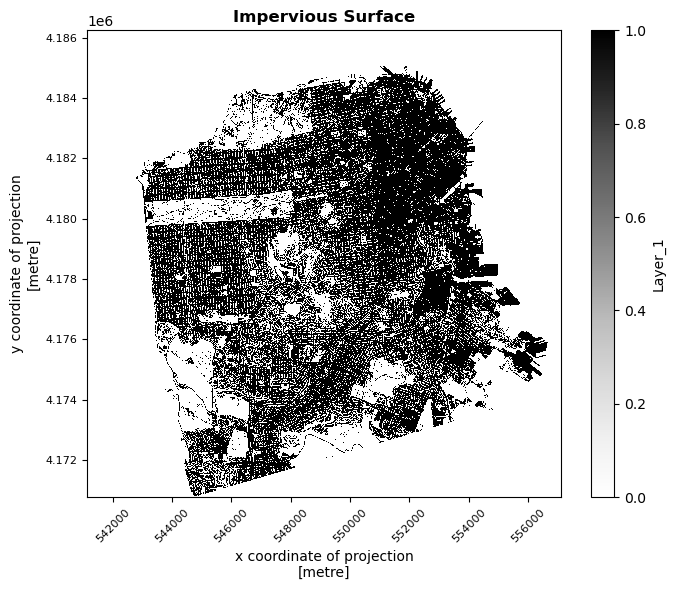

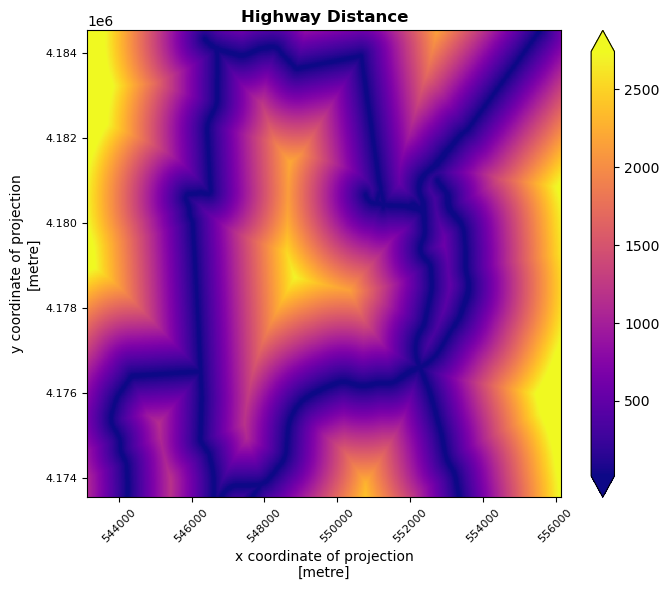

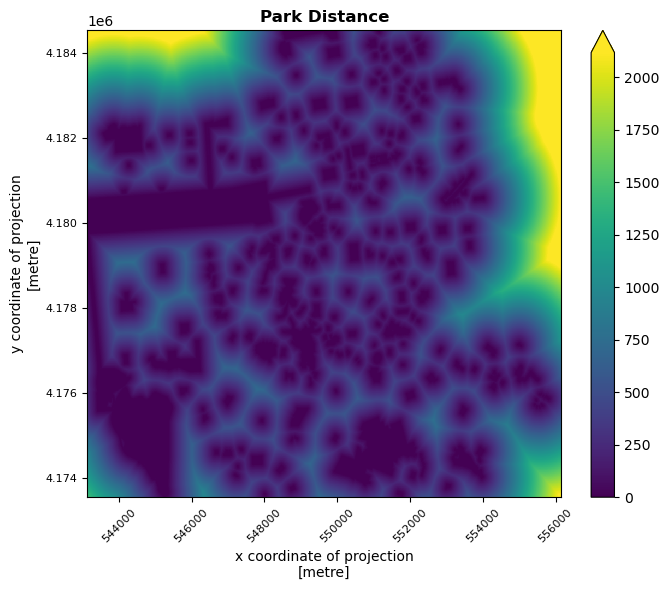

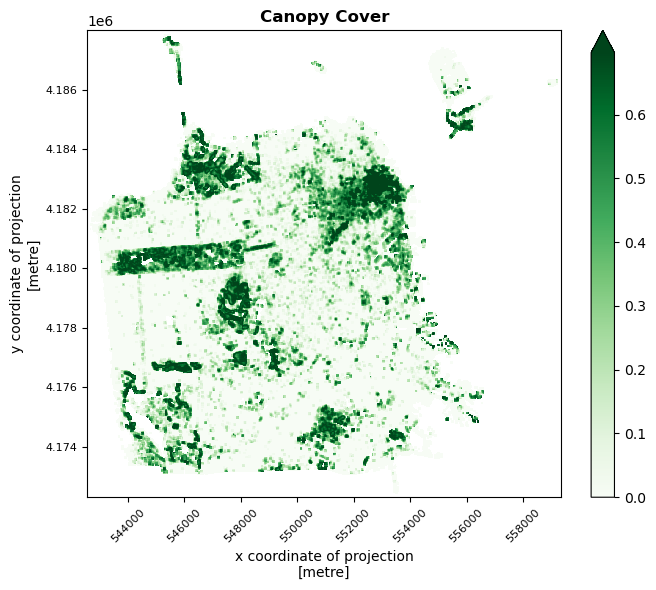

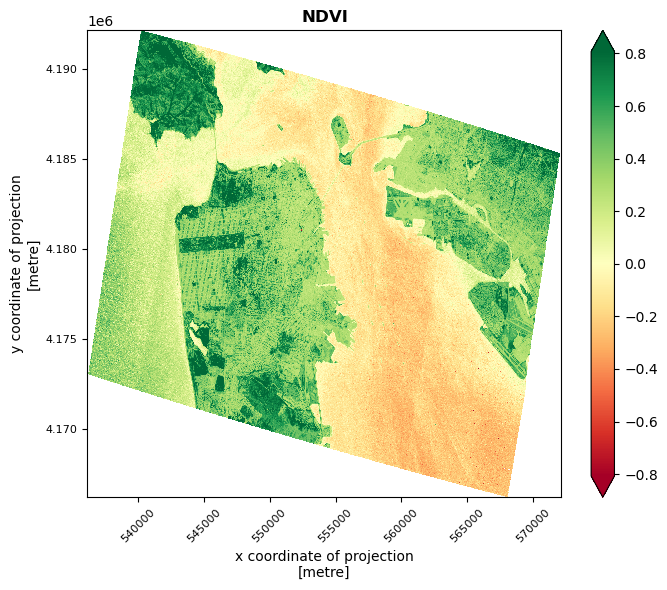

: 

In [ ]:
import os

downsample = 5
out_dir = "../results_images"
os.makedirs(out_dir, exist_ok=True)
date = "4.16.26"

layers = [
    # (raster,     title,                 colormap,  file name)
    (imperm_prj,  "Impervious Surface",  "Greys",   "impervious"),
    (highway_prj, "Highway Distance",    "plasma",  "highway_dist"),
    (parks_prj,   "Park Distance",       "viridis",  "park_dist"),
    (canopy_prj,  "Canopy Cover",        "Greens",  "canopy"),
    (ndvi_prj,    "NDVI",                "RdYlGn",  "ndvi"),
]

for da, title, cmap, fname in layers:
    fig, ax = plt.subplots(figsize=(7, 6))
    da[::downsample, ::downsample].plot(ax=ax, cmap=cmap, robust=True)
    ax.set_title(title, fontweight="bold")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
    fig.tight_layout()
    fig.savefig(f"{out_dir}/{fname}_{date}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)   # frees memory so figures don't pile up


In [ ]:
#%pip install contextily
import contextily as ctx

# Get the bounds of the raster
left, bottom, right, top = ndvi_prj.rio.bounds()

fig, ax = plt.subplots(figsize=(12, 8))

# Plot a downsampled version of the raster
im = ax.imshow(ndvi_prj, extent=[left, right, bottom, top], 
               cmap='RdYlGn')

# Add a basemap
#ctx.add_basemap(ax, crs=ndvi.rio.crs.to_string(), source=ctx.providers.OpenStreetMap.Mapnik)

plt.colorbar(im, label='NDVI')
plt.title('NDVI with Basemap')
plt.axis('off')
plt.show()

# Raster Stats

In [17]:
# ============================================================================
# RASTER ZONAL STATS for every hexagon scale
# ============================================================================
from rasterstats import zonal_stats

STATS = ["min", "max", "mean", "count", "median", "std", "majority"]

# Read each raster into memory once and reuse it for every scale
RASTERS = {name: (da.values, da.rio.transform()) for name, da in {
    "ndvi":    ndvi_prj,
    "highway": highway_prj,
    "parks":   parks_prj,          # now uses its own transform (the old cell used highway's)
    "imperm":  imperm_prj,
    "canopy":  canopy_prj,
}.items()}

raster_by_scale = {}
for scale, hexes in hex_by_scale.items():
    out = hexes.copy()
    for name, (arr, affine) in RASTERS.items():
        zs = zonal_stats(hexes.geometry, arr, affine=affine, nodata=np.nan,
                         all_touched=True, stats=STATS)
        out = out.join(pd.DataFrame(zs).add_suffix(f"_{name}"))
    raster_by_scale[scale] = out

    print(f"\n{scale}: {len(out)} hexagons, NA counts:")
    print(out[[f"mean_{n}" for n in RASTERS]].isna().sum().to_string())

result_gdf = raster_by_scale["sf_100"]   # alias for the old cells


sf_10: 1048 hexagons, NA counts:
mean_ndvi       0
mean_highway    0
mean_parks      0
mean_imperm     0
mean_canopy     3

sf_100: 715 hexagons, NA counts:
mean_ndvi       0
mean_highway    0
mean_parks      0
mean_imperm     0
mean_canopy     0

sf_250: 381 hexagons, NA counts:
mean_ndvi       0
mean_highway    0
mean_parks      0
mean_imperm     0
mean_canopy     0

sf_500: 140 hexagons, NA counts:
mean_ndvi       0
mean_highway    0
mean_parks      0
mean_imperm     0
mean_canopy     0


Canopy NoData value: nan
Canopy has NaN: 15307696
Canopy value range: 0.0 to 1.3112495


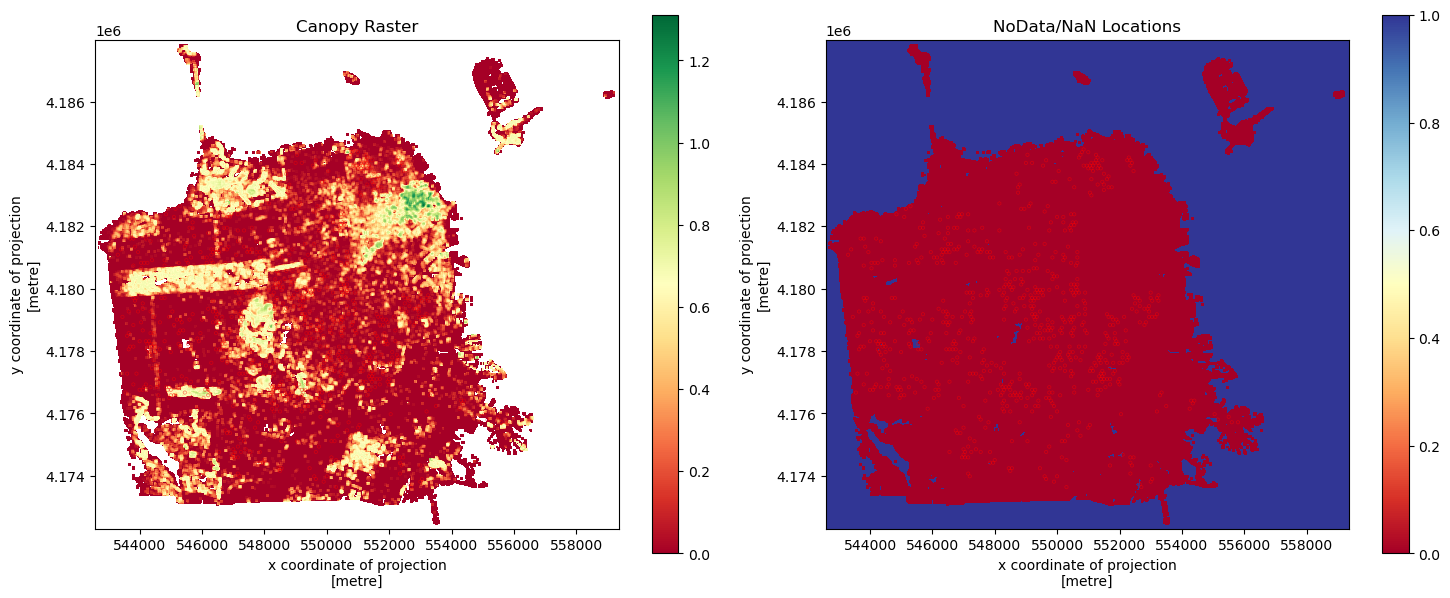

In [18]:
# Check NoData handling
print("Canopy NoData value:", canopy_prj.rio.nodata)
print("Canopy has NaN:", canopy_prj.isnull().sum().values)
print("Canopy value range:", canopy_prj.min().values, "to", canopy_prj.max().values)

# Visualize NoData locations
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Plot raster
canopy_prj.plot(ax=ax[0], cmap='RdYlGn')
ax[0].set_title('Canopy Raster')

# Plot NaN mask
canopy_prj.isnull().plot(ax=ax[1], cmap='RdYlBu')
ax[1].set_title('NoData/NaN Locations')

# Overlay hexagons
hex_prj_clean.boundary.plot(ax=ax[0], color='red', linewidth=0.5, alpha=0.5)
hex_prj_clean.boundary.plot(ax=ax[1], color='red', linewidth=0.5, alpha=0.5)
plt.tight_layout()
plt.show()

# NHGIS Percentages

In [19]:

nhgis_prj = nhgis_prj[['AMP3E001', 'AMP3E003', 'AMP3E004', 'AMP3E005', 'AMP3E006', 
                       'AMP3E007', 'AMP3E008', 'AMR8E001', 'AMP3E012', 'geometry']]
                       

nhgis_prj = nhgis_prj.rename(columns={
    'AMP3E001': 'TOTPOP',
    'AMP3E003': 'NH_WHITE',
    'AMP3E004': 'NH_BLACK',
    'AMP3E005': 'NH_AMIN',
    'AMP3E006': 'NH_ASIAN',
    'AMP3E007': 'NH_NHPI',
    'AMP3E008': 'NH_OTHER',
    'AMR8E001': 'MED_INCOME',
    'AMP3E012': 'LATINE'
})


#nhgis_join = gpd.sjoin(hex_prj_clean, nhgis_prj1, how='inner', predicate='intersects') #check if it works using .head()


"""
# Create percentage columns for each demographic group
nhgis_join['WHITE_PER'] = nhgis_join['NH_WHITE'] / nhgis_join['TOTPOP']
nhgis_join['BLACK_PER'] = nhgis_join['NH_BLACK'] / nhgis_join['TOTPOP']
nhgis_join['AMIN_PER'] = nhgis_join['NH_AMIN'] / nhgis_join['TOTPOP']
nhgis_join['ASIAN_PER'] = nhgis_join['NH_ASIAN'] / nhgis_join['TOTPOP']
nhgis_join['NHPI_PER'] = nhgis_join['NH_NHPI'] / nhgis_join['TOTPOP']
nhgis_join['OTHER_PER'] = nhgis_join['NH_OTHER'] / nhgis_join['TOTPOP']
nhgis_join['LATINE_PER'] = nhgis_join['LATINE'] / nhgis_join['TOTPOP']

# Handle any potential division by zero errors (if there are census tracts with zero population)
percentage_columns = ['WHITE_PER', 'BLACK_PER', 'AMIN_PER', 'ASIAN_PER', 'NHPI_PER', 'OTHER_PER', 'LATINE_PER']
nhgis_join[percentage_columns] = nhgis_join[percentage_columns].fillna(0)

# You might want to multiply by 100 to get actual percentages
nhgis_join[percentage_columns] = nhgis_join[percentage_columns] * 100

# Check the new columns
print(nhgis_join[['TOTPOP'] + percentage_columns].head())

"""

"\n# Create percentage columns for each demographic group\nnhgis_join['WHITE_PER'] = nhgis_join['NH_WHITE'] / nhgis_join['TOTPOP']\nnhgis_join['BLACK_PER'] = nhgis_join['NH_BLACK'] / nhgis_join['TOTPOP']\nnhgis_join['AMIN_PER'] = nhgis_join['NH_AMIN'] / nhgis_join['TOTPOP']\nnhgis_join['ASIAN_PER'] = nhgis_join['NH_ASIAN'] / nhgis_join['TOTPOP']\nnhgis_join['NHPI_PER'] = nhgis_join['NH_NHPI'] / nhgis_join['TOTPOP']\nnhgis_join['OTHER_PER'] = nhgis_join['NH_OTHER'] / nhgis_join['TOTPOP']\nnhgis_join['LATINE_PER'] = nhgis_join['LATINE'] / nhgis_join['TOTPOP']\n\n# Handle any potential division by zero errors (if there are census tracts with zero population)\npercentage_columns = ['WHITE_PER', 'BLACK_PER', 'AMIN_PER', 'ASIAN_PER', 'NHPI_PER', 'OTHER_PER', 'LATINE_PER']\nnhgis_join[percentage_columns] = nhgis_join[percentage_columns].fillna(0)\n\n# You might want to multiply by 100 to get actual percentages\nnhgis_join[percentage_columns] = nhgis_join[percentage_columns] * 100\n\n# Check t

In [ ]:

# ============================================================
# COMPLETE WORKFLOW WITH POPULATION DENSITY
# ============================================================


def calculate_hex_demographics_with_density(hex_prj_clean, nhgis_prj):
    """
    Complete workflow: demographics + population density
    """
    # 1. CLEAN MEDIAN INCOME DATA FIRST
    print("=" * 60)
    print("CLEANING MEDIAN INCOME DATA")
    print("=" * 60)
    
    # Check for negative/invalid values
    invalid_income = nhgis_prj[nhgis_prj['MED_INCOME'] < 0]
    print(f"Block groups with invalid income: {len(invalid_income)}/{len(nhgis_prj)}")
    
    if len(invalid_income) > 0:
        print(f"Invalid income values found: {invalid_income['MED_INCOME'].unique()}")
    
    # Replace invalid values with NaN
    nhgis_prj['MED_INCOME'] = nhgis_prj['MED_INCOME'].apply(
        lambda x: np.nan if x < 0 else x
    )
    
    # 1. Calculate percentages on block groups
    demographic_cols = ['NH_WHITE', 'NH_BLACK', 'NH_AMIN', 'NH_ASIAN', 
                       'NH_NHPI', 'NH_OTHER', 'LATINE']
    
    for col in demographic_cols:
        pct_col = col + '_PER'
        nhgis_prj[pct_col] = np.where(
            nhgis_prj['TOTPOP'] > 0,
            (nhgis_prj[col] / nhgis_prj['TOTPOP']) * 100,
            0
        )
    
    # POC percentage
    nhgis_prj['POC_PER'] = np.where(
        nhgis_prj['TOTPOP'] > 0,
        ((nhgis_prj['NH_BLACK'] + nhgis_prj['NH_AMIN'] + nhgis_prj['NH_ASIAN'] + 
          nhgis_prj['NH_NHPI'] + nhgis_prj['NH_OTHER'] + nhgis_prj['LATINE']) / 
         nhgis_prj['TOTPOP']) * 100,
        0
    )
    
    # Block group area and density
    nhgis_prj['bg_area_sqkm'] = nhgis_prj.geometry.area / 1_000_000
    nhgis_prj['bg_pop_density'] = np.where(
        nhgis_prj['bg_area_sqkm'] > 0,
        nhgis_prj['TOTPOP'] / nhgis_prj['bg_area_sqkm'],
        0
    )
    
    # 2. Spatial join
    nhgis_join = gpd.sjoin(hex_prj_clean, nhgis_prj, how='left', predicate='intersects')
    
    # 3. Population-weighted aggregation
    def weighted_average(group, value_col, weight_col='TOTPOP'):
        weights = group[weight_col]
        values = group[value_col]
        if weights.sum() == 0:
            return 0
        return (values * weights).sum() / weights.sum()
    
    # Demographic percentage columns
    demographic_pct_cols = ['NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 
                           'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 
                           'LATINE_PER', 'POC_PER']
    
    # Aggregation dictionary
    agg_dict = {
        'TOTPOP': 'sum',
        'MED_INCOME': lambda x: weighted_average(
            pd.DataFrame({'MED_INCOME': nhgis_join.loc[x.index, 'MED_INCOME'], 
                         'TOTPOP': nhgis_join.loc[x.index, 'TOTPOP']}), 
            'MED_INCOME'
        )
    }
    
    # Add demographic percentages
    for col in demographic_pct_cols:
        agg_dict[col] = lambda x, col=col: weighted_average(
            pd.DataFrame({col: nhgis_join.loc[x.index, col], 
                         'TOTPOP': nhgis_join.loc[x.index, 'TOTPOP']}), 
            col
        )
    
    # Aggregate by hexagon
    hex_demographics = nhgis_join.groupby('hex_id').agg(agg_dict).reset_index()
    
    # 4. Calculate hexagon area
    hex_prj_clean['area_sqkm'] = hex_prj_clean.geometry.area / 1_000_000
    hex_prj_clean['area_sqm'] = hex_prj_clean.geometry.area
    
    # 5. Merge area to demographics
    hex_demographics = hex_demographics.merge(
        hex_prj_clean[['hex_id', 'area_sqkm', 'area_sqm']], 
        on='hex_id', 
        how='left'
    )
    
    # 6. Calculate population density
    hex_demographics['pop_density_sqkm'] = np.where(
        hex_demographics['area_sqkm'] > 0,
        hex_demographics['TOTPOP'] / hex_demographics['area_sqkm'],
        0
    )
    
    hex_demographics['pop_density_sqm'] = np.where(
        hex_demographics['area_sqm'] > 0,
        hex_demographics['TOTPOP'] / hex_demographics['area_sqm'],
        0
    )
    
    
    # 7. Merge back to hexagon geometry
    hex_final = hex_prj_clean.merge(hex_demographics, on='hex_id', how='left')
    
    # Remove duplicate area columns
    hex_final = hex_final.drop(columns=['area_sqkm_y', 'area_sqm_y'], errors='ignore')
    hex_final = hex_final.rename(columns={
        'area_sqkm_x': 'area_sqkm',
        'area_sqm_x': 'area_sqm'    })
    
    return hex_final

# Run the complete workflow
# hex_final = calculate_hex_demographics_with_density(hex_prj_clean, nhgis_prj)

# ============================================================
# SUMMARY STATISTICS
# ============================================================

print("\n" + "=" * 60)
print("FINAL DATASET SUMMARY")
print("=" * 60)
print(f"Total hexagons: {len(hex_final)}")
print(f"\nColumns: {list(hex_final.columns)}")

print("\n" + "=" * 60)
print("POPULATION DENSITY STATISTICS")
print("=" * 60)
print("\nPer Square Kilometer:")
print(hex_final['pop_density_sqkm'].describe())

# Sample data
print("\n" + "=" * 60)
print("SAMPLE DATA")
print("=" * 60)
print(hex_final.head())




CLEANING MEDIAN INCOME DATA
Block groups with invalid income: 0/679

FINAL DATASET SUMMARY
Total hexagons: 715

Columns: ['hex_id', 'grade', 'hex_scale', 'geometry', 'area_m2', 'area_sqkm', 'area_sqm', 'TOTPOP', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', 'pop_density_sqm']

POPULATION DENSITY STATISTICS

Per Square Kilometer:
count       715.000000
mean     273282.088187
std      137782.431932
min       41684.689435
25%      157501.153435
50%      253225.828067
75%      349065.972753
max      889927.704929
Name: pop_density_sqkm, dtype: float64

SAMPLE DATA
  hex_id grade hex_scale                                           geometry  \
0    2_B     B    sf_100  POLYGON ((543295.991 4181028.379, 543245.991 4...   
1   15_B     B    sf_100  POLYGON ((543395.991 4181201.584, 543345.991 4...   
2   21_C     C    sf_100  POLYGON ((543445.991 4179036.521, 543395.991 4...   
3   44_B  

In [23]:
# ============================================================================
# POLYGONS (census + zoning) and FINAL FEATURE TABLE for every hexagon scale
# ============================================================================
ZONE_NAMES = {0.0: "other_zone_pct",   # code 0: zoning class that isn't 1 (single-family) or 2 (multi-family)
              1.0: "SF_pct",           # single-family residential
              2.0: "MF_pct"}           # multi-family residential

def zoning_percentages(hexes, zone):
    """% of each hexagon's area in each zoning class (one column per class)."""
    ov = gpd.overlay(hexes[["hex_id", "geometry"]], zone[["Zoning", "geometry"]],
                     how="intersection", keep_geom_type=True)
    ov["intersection_area"] = ov.area
    area = ov.groupby(["hex_id", "Zoning"])["intersection_area"].sum()
    pct  = area.div(hexes.set_index("hex_id")["area_m2"], level="hex_id") * 100
    out  = pct.unstack(fill_value=0).rename(columns=ZONE_NAMES)
    out.columns = out.columns.map(str)          # any unexpected code still becomes a string name
    out.columns.name = None
    return out.reset_index()

features_by_scale = {}

for scale, hexes in hex_by_scale.items():
    print(f"\n{'#' * 60}\n{scale}\n{'#' * 60}")

    # Census demographics + population density (the function adds columns, so pass a copy)
    demo = calculate_hex_demographics_with_density(hexes.copy(), nhgis_prj)
    demo = demo[["hex_id"] + [c for c in demo.columns if c not in hexes.columns]]

    # Zoning % per hexagon
    zoning = zoning_percentages(hexes, zone_sf_prj)
    zoning_cols = [c for c in zoning.columns if c != "hex_id"]

    feats = (raster_by_scale[scale]
               .merge(demo,   on="hex_id", how="left")
               .merge(zoning, on="hex_id", how="left"))
    feats[zoning_cols] = feats[zoning_cols].fillna(0)   # hexagons with no zoning polygon get 0 %
    features_by_scale[scale] = feats

    assert feats["hex_id"].is_unique, f"{scale}: duplicate hex_ids after the joins"
    print(f"{scale}: {feats.shape[0]} hexagons x {feats.shape[1]} columns")

    size = scale.split("_")[1]
    feats.to_parquet(f"{hex_dir}/sfhex_{size}_features_{DATE}.parquet")

df5 = features_by_scale["sf_100"]   # alias for the old iNEXT-merge cells


############################################################
sf_10
############################################################
CLEANING MEDIAN INCOME DATA
Block groups with invalid income: 0/679
sf_10: 1048 hexagons x 56 columns

############################################################
sf_100
############################################################
CLEANING MEDIAN INCOME DATA
Block groups with invalid income: 0/679
sf_100: 715 hexagons x 55 columns

############################################################
sf_250
############################################################
CLEANING MEDIAN INCOME DATA
Block groups with invalid income: 0/679
sf_250: 381 hexagons x 57 columns

############################################################
sf_500
############################################################
CLEANING MEDIAN INCOME DATA
Block groups with invalid income: 0/679
sf_500: 140 hexagons x 57 columns


# Final Hexagons

In [25]:
df5

,hex_id,grade,hex_scale,geometry,area_m2,min_ndvi,max_ndvi,mean_ndvi,count_ndvi,std_ndvi,...,NH_ASIAN_PER,NH_NHPI_PER,NH_OTHER_PER,LATINE_PER,POC_PER,pop_density_sqkm,pop_density_sqm,other_zone_pct,SF_pct,MF_pct
0,2_B,B,sf_100,"POLYGON ((543295.991 4181028.379, 543245.991 4...",8660.254038,0.222622,0.721383,0.375136,1048,0.081965,...,27.075472,0.000000,0.000000,10.471698,38.962264,122398.257069,0.122398,0.0,11.271811,47.543241
1,15_B,B,sf_100,"POLYGON ((543395.991 4181201.584, 543345.991 4...",8660.254038,0.254963,0.699268,0.416139,1029,0.107304,...,26.881720,0.000000,0.000000,11.520737,39.170507,225513.015145,0.225513,0.0,72.254537,0.000000
2,21_C,C,sf_100,"POLYGON ((543445.991 4179036.521, 543395.991 4...",8660.254038,0.213248,0.669190,0.378044,1048,0.093760,...,36.205899,4.222094,0.000000,18.478890,61.307114,399295.446171,0.399295,0.0,64.353890,0.000000
3,44_B,B,sf_100,"POLYGON ((543545.991 4176611.65, 543495.991 41...",8660.254038,0.218430,0.544557,0.316655,1030,0.057492,...,25.264350,0.000000,0.453172,0.000000,25.717523,305764.702564,0.305765,0.0,38.019513,0.000000
4,65_B,B,sf_100,"POLYGON ((543595.991 4177217.868, 543545.991 4...",8660.254038,0.209496,0.551691,0.314890,1050,0.062287,...,49.030172,0.000000,1.760057,8.369253,61.566092,321468.629884,0.321469,0.0,17.278626,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
710,6004_D,D,sf_100,"POLYGON ((552995.991 4179642.739, 552945.991 4...",8660.254038,0.216396,0.690324,0.381918,1030,0.103564,...,20.902806,0.000000,1.342009,11.102074,34.729565,283940.862387,0.283941,0.0,0.000000,73.221331
711,6005_D,D,sf_100,"POLYGON ((552995.991 4179815.944, 552945.991 4...",8660.254038,0.205325,0.768603,0.364180,1028,0.125804,...,24.385582,0.000000,5.051884,8.492627,38.858547,422851.337153,0.422851,0.0,0.000000,57.126581
712,6007_D,D,sf_100,"POLYGON ((553045.991 4179036.521, 552995.991 4...",8660.254038,0.250044,0.733235,0.500393,1048,0.117082,...,24.542358,0.000000,0.000000,13.516390,38.739889,542478.312930,0.542478,0.0,0.000000,54.562557
713,6017_D,D,sf_100,"POLYGON ((553145.991 4179036.521, 553095.991 4...",8660.254038,0.274716,0.751880,0.475144,1030,0.103370,...,33.750000,0.000000,0.000000,21.791667,56.875000,277128.129211,0.277128,0.0,0.000000,43.388587


In [27]:
# ============================================================================
# Merge the all-species asymptotic iNEXT estimates (from Sherlock) for every scale
# ============================================================================
import glob

inext_dir = f"{hex_dir}/inext_results"          # results/<scale>/ copied back from Sherlock

inext_values_by_scale, df6_by_scale = {}, {}

for scale, df5_s in features_by_scale.items():
    size  = scale.split("_")[1]
    files = sorted(glob.glob(f"{inext_dir}/{scale}/SF_{size}hex_inc_asymp_hex_*.csv"),
                   key=os.path.getmtime)
    if not files:
        print(f"{scale}: no asymp file found in {inext_dir}/{scale}/, skipped")
        continue

    inext_values = pd.read_csv(files[-1])       # newest run
    inext_values["Assemblage"] = inext_values["Assemblage"].astype(str).str.strip()
    inext_values_by_scale[scale] = inext_values

    df6_s = df5_s.merge(inext_values, left_on="hex_id", right_on="Assemblage", how="left")
    df6_by_scale[scale] = df6_s

    n_hex     = df5_s["hex_id"].nunique()
    n_matched = df6_s.loc[df6_s["Assemblage"].notna(), "hex_id"].nunique()
    print(f"{scale}: {os.path.basename(files[-1])}")
    print(f"   {df6_s.shape[0]} rows x {df6_s.shape[1]} cols | "
          f"{n_matched}/{n_hex} hexagons have iNEXT estimates "
          f"(rows per hexagon: {df6_s.groupby('hex_id').size().max()}, one per q)")

df6 = df6_by_scale.get("sf_100")                # alias for the old single-scale cells
if df6 is not None:
    print(df6.columns.tolist())

sf_10: SF_10hex_inc_asymp_hex_11_22_26.csv
   1394 rows x 63 cols | 173/1048 hexagons have iNEXT estimates (rows per hexagon: 3, one per q)
sf_100: SF_100hex_inc_asymp_hex_11_22_26.csv
   1009 rows x 62 cols | 147/715 hexagons have iNEXT estimates (rows per hexagon: 3, one per q)
sf_250: SF_250hex_inc_asymp_hex_11_22_26.csv
   677 rows x 64 cols | 148/381 hexagons have iNEXT estimates (rows per hexagon: 3, one per q)
sf_500: SF_500hex_inc_asymp_hex_11_22_26.csv
   334 rows x 64 cols | 97/140 hexagons have iNEXT estimates (rows per hexagon: 3, one per q)
['hex_id', 'grade', 'hex_scale', 'geometry', 'area_m2', 'min_ndvi', 'max_ndvi', 'mean_ndvi', 'count_ndvi', 'std_ndvi', 'median_ndvi', 'majority_ndvi', 'min_highway', 'max_highway', 'mean_highway', 'count_highway', 'std_highway', 'median_highway', 'majority_highway', 'min_parks', 'max_parks', 'mean_parks', 'count_parks', 'std_parks', 'median_parks', 'majority_parks', 'min_imperm', 'max_imperm', 'mean_imperm', 'count_imperm', 'std_imperm'

In [28]:
# Check for duplicates in your key columns
print("=== DUPLICATES CHECK ===")

# Check df5
print(f"\ndf5 shape: {df5.shape}")
print(f"Unique hex_ids in df5: {df5['hex_id'].nunique()}")
print(f"Duplicate hex_ids in df5: {df5['hex_id'].duplicated().sum()}")

# Check inext_values
print(f"\ninext_values shape: {inext_values.shape}")
print(f"Unique Assemblages in inext_values: {inext_values['Assemblage'].nunique()}")
print(f"Duplicate Assemblages: {inext_values['Assemblage'].duplicated().sum()}")

# Check what columns inext has
print(f"\ninext_values columns: {inext_values.columns.tolist()}")

# See the diversity types
if 'Diversity' in inext_values.columns:
    print(f"\nDiversity types in inext_values:")
    print(inext_values['Diversity'].value_counts())

# Check how many rows per Assemblage
print(f"\nRows per Assemblage in inext_values:")
print(inext_values.groupby('Assemblage').size().describe())

=== DUPLICATES CHECK ===

df5 shape: (715, 55)
Unique hex_ids in df5: 715
Duplicate hex_ids in df5: 0

inext_values shape: (291, 7)
Unique Assemblages in inext_values: 97
Duplicate Assemblages: 194

inext_values columns: ['Assemblage', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']

Diversity types in inext_values:
Diversity
Species richness     97
Shannon diversity    97
Simpson diversity    97
Name: count, dtype: int64

Rows per Assemblage in inext_values:
count    97.0
mean      3.0
std       0.0
min       3.0
25%       3.0
50%       3.0
75%       3.0
max       3.0
dtype: float64


# Habitat

In [30]:
# ============================================================================
# Load the iNEXT results from Sherlock for every scale x guild
#   inext_results/<scale>/<scale>_ebird_<guild>_inc_covstd_0.8.csv
# ============================================================================
res_dir = "/home/oliver/Documents/redlining/code/data/SF/inext_results"
LEVEL   = 0.8
SCALES  = ["sf_10", "sf_100", "sf_250", "sf_500"]
GUILDS  = ["trees", "water", "shrubgrass", "urban", "native", "nonnative", "all"]

inext_raw = {}                     # inext_raw["sf_250"]["trees"] -> DataFrame
for scale in SCALES:
    inext_raw[scale] = {}
    for guild in GUILDS:
        path = f"{res_dir}/{scale}/{scale}_ebird_{guild}_inc_covstd_{LEVEL}.csv"
        if not os.path.exists(path):
            print(f"missing: {path}")
            continue
        df = pd.read_csv(path)
        df["Assemblage"] = df["Assemblage"].astype(str).str.strip()
        inext_raw[scale][guild] = df

# Summary: hexagons with estimates per scale x guild
print(pd.DataFrame({s: {g: d["Assemblage"].nunique() for g, d in gd.items()}
                    for s, gd in inext_raw.items()}).T)

# Old names (sf_100) so any later single-scale code still runs
inext_data_human      = inext_raw["sf_100"]["urban"]
inext_data_shrubgrass = inext_raw["sf_100"]["shrubgrass"]
inext_data_tree       = inext_raw["sf_100"]["trees"]
inext_data_water      = inext_raw["sf_100"]["water"]
inext_data_native     = inext_raw["sf_100"]["native"]
inext_data_nonnative  = inext_raw["sf_100"]["nonnative"]
inext_data_all        = inext_raw["sf_100"]["all"]

        trees  water  shrubgrass  urban  native  nonnative  all
sf_10     266    132         208    167     341        144  352
sf_100    262    120         184    157     315        141  323
sf_250    204    123         175    152     239        143  241
sf_500    109     82         100     97     122         92  123


In [ ]:
# ============================================================================
# Guild iNEXT estimates (fixed 80 % coverage) for every hexagon scale
# ============================================================================
import itertools

res_dir = f"{hex_dir}/inext_results"     # results/<scale>/ copied back from Sherlock
LEVEL   = 0.8
q_names = {0: "Species richness", 1: "Shannon diversity", 2: "Simpson diversity"}

# column prefix -> guild name in the Sherlock file names
# (old prefixes kept, so P5's human_estimate / tree_estimate still work)
groups = {"human": "urban", "water": "water", "tree": "trees", "shrubgrass": "shrubgrass",
          "native": "native", "nonnative": "nonnative", "all": "all"}

def load_covstd(scale, guild):
    path = f"{res_dir}/{scale}/{scale}_ebird_{guild}_inc_covstd_{LEVEL}.csv"
    if not os.path.exists(path):
        print(f"   missing: {os.path.basename(path)}")
        return None
    df = pd.read_csv(path)
    df = df.rename(columns={"Assemblage": "label", "qD": "Estimator",
                            "qD.LCL": "LCL", "qD.UCL": "UCL"})
    df["label"] = df["label"].astype(str).str.strip().str.lstrip("X").str.upper()
    df["Diversity"] = df["Order.q"].map(q_names)
    return df[["label", "Diversity", "Estimator", "LCL", "UCL", "beyond_2T"]]

result_df_by_scale = {}
for scale in SCALES:
    print(f"\n{'#' * 60}\n{scale}\n{'#' * 60}")
    inext = {name: d for name, g in groups.items()
             if (d := load_covstd(scale, g)) is not None}
    if not inext:
        print(f"{scale}: no iNEXT files found, skipped")
        continue

    # Base table: every hexagon x diversity order (hexagons that failed for a guild stay NaN)
    all_labels = sorted(set().union(*[d["label"] for d in inext.values()]))
    result_df = pd.DataFrame(itertools.product(all_labels, q_names.values()),
                             columns=["label", "Diversity"])

    for name, d in inext.items():
        d = d.rename(columns={"Estimator": f"{name}_estimate", "LCL": f"{name}_lcl",
                              "UCL": f"{name}_ucl", "beyond_2T": f"{name}_beyond2T"})
        result_df = result_df.merge(d, on=["label", "Diversity"], how="left")

    result_df = result_df.rename(columns={"label": "hex_id"})
    result_df["grade"] = result_df["hex_id"].str.split("_").str[-1]
    result_df["hex_scale"] = scale
    result_df_by_scale[scale] = result_df

    print(f"{scale}: {result_df.shape[0]} rows ({result_df['hex_id'].nunique()} hexagons) "
          f"x {result_df.shape[1]} cols")
    print("Missing estimates per guild (failed or absent):")
    print(result_df.filter(like="_estimate").isna().groupby(result_df["Diversity"]).sum())

result_df = result_df_by_scale.get("sf_100")   # alias for the old single-scale cells


############################################################
sf_10
############################################################
sf_10: 1077 rows (359 hexagons) x 32 cols
Missing estimates per guild (failed or absent):
                   human_estimate  water_estimate  tree_estimate  \
Diversity                                                          
Shannon diversity             192             227             93   
Simpson diversity             192             227             93   
Species richness              192             227             93   

                   shrubgrass_estimate  native_estimate  nonnative_estimate  \
Diversity                                                                     
Shannon diversity                  151               18                 215   
Simpson diversity                  151               18                 215   
Species richness                   151               18                 215   

                   all_estimate  
Diversity 

In [ ]:
""" 
# Check column names in each dataframe
print("Column names in each dataframe:")
for df_name, df in {
    'all': inext_data_all,
    'human': inext_data_human,
    'water': inext_data_water,
    'tree': inext_data_tree,
    'shrubgrass': inext_data_shrubgrass,
    'native' : inext_data_native,
    'nonnative' : inext_data_nonnative
}.items():
    print(f"{df_name}: {df.columns.tolist()}")

# Standardize column names across all dataframes
for df in [inext_data_all, inext_data_human, inext_data_water, inext_data_tree, inext_data_shrubgrass, inext_data_native, inext_data_nonnative]:
    if 'Assemblage' in df.columns:
        df.rename(columns={'Assemblage': 'label'}, inplace=True)
    
    # Clean IDs for consistency
    if 'label' in df.columns:
        df['label'] = df['label'].str.strip().str.upper()

# Create the base dataframe with unique combinations of label and Diversity
# First, collect all unique labels and diversity metrics
all_labels = set()
all_diversity = set()

for df in [inext_data_all, inext_data_human, inext_data_water, inext_data_tree, inext_data_shrubgrass, inext_data_native, inext_data_nonnative]:
    if 'label' in df.columns:
        all_labels.update(df['label'].unique())
    if 'Diversity' in df.columns:
        all_diversity.update(df['Diversity'].unique())

# Convert sets to lists for DataFrame creation
all_labels = list(all_labels)
all_diversity = list(all_diversity)

# Create all combinations
import itertools
combinations = list(itertools.product(all_labels, all_diversity))
base_df = pd.DataFrame(combinations, columns=['label', 'Diversity'])

# Function to add each habitat's estimates
def add_habitat_estimates(base_df, habitat_df, habitat_name):
    """
    Adds estimate columns from a habitat dataset to the base dataframe
    """
    # Make a copy of the input dataframe
    df = habitat_df.copy()
    
    # Ensure we have the correct column names
    if 'Estimator' in df.columns:
        # Create a new dataframe with the columns we need
        temp_df = df[['label', 'Diversity', 'Estimator']].copy()
        # Rename the estimate column
        temp_df = temp_df.rename(columns={'Estimator': f'{habitat_name}_estimate'})
        
        # Merge with the base dataframe
        merged_df = base_df.merge(temp_df, on=['label', 'Diversity'], how='left')
        return merged_df
    else:
        print(f"Warning: 'Estimator' column not found in {habitat_name} dataframe. Columns: {df.columns.tolist()}")
        return base_df

# Start with the base dataframe
result_df = base_df.copy()

# Add estimates from each habitat type
habitat_types = {
    'human': inext_data_human,
    'water': inext_data_water,
    'tree': inext_data_tree,
    'shrubgrass': inext_data_shrubgrass,
    'native': inext_data_native,
    'nonnative': inext_data_nonnative,
    'all': inext_data_all
}

for habitat_name, habitat_df in habitat_types.items():
    print(f"Processing {habitat_name} habitat data...")
    result_df = add_habitat_estimates(result_df, habitat_df, habitat_name)

# Add additional columns from holc_prj 
# (First, make sure 'label' in holc_prj is standardized)
if 'label' in holc_prj.columns:
    holc_prj['label'] = holc_prj['label'].str.strip().str.upper()
    
    # Add all columns except 'label' (which is already in result_df)
    other_columns = [col for col in holc_prj.columns if col != 'label']
    if other_columns:  # Only merge if there are columns to add
        result_df = result_df.merge(holc_prj[['label'] + other_columns], on='label', how='left')

# Display the results
print("\nFinal dataframe shape:", result_df.shape)
print("Columns in final dataframe:", result_df.columns.tolist())
print("\nSample rows from final dataframe:")
print(result_df.head())

# Check for missing values
print("\nMissing value counts by column:")
print(result_df.isna().sum()) """

Column names in each dataframe:
all: ['Unnamed: 0', 'label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
human: ['label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
water: ['label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
tree: ['label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
shrubgrass: ['label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
native: ['label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
nonnative: ['label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
Processing human habitat data...
Processing water habitat data...
Processing tree habitat data...
Processing shrubgrass habitat data...
Processing native habitat data...
Processing nonnative habitat data...
Processing all habitat data...

Final dataframe shape: (759, 20)
Columns in final dataframe: ['label', 'Diversity', 'human_estimate', 'water_estimate', 'tree_estimate', 'shrubgrass_estimate', 'native_e

In [ ]:
result_df.shape

(459, 27)

In [33]:
# Join features to the iNEXT estimates for every scale
# (iNEXT table first, so only hexagons with estimates are kept)
final_by_scale = {s: r.merge(features_by_scale[s], on="hex_id", how="left", suffixes=("", "_feat"))
                  for s, r in result_df_by_scale.items()}

for s, f in final_by_scale.items():
    print(f"{s}: {f.shape[0]} rows, {f['hex_id'].nunique()} hexagons, "
          f"max rows per hexagon = {f.groupby('hex_id').size().max()}")   # should be 3 (one per q)

final = final_by_scale["sf_100"]   # alias for the cells below

sf_10: 1077 rows, 359 hexagons, max rows per hexagon = 3
sf_100: 984 rows, 328 hexagons, max rows per hexagon = 3
sf_250: 729 rows, 243 hexagons, max rows per hexagon = 3
sf_500: 369 rows, 123 hexagons, max rows per hexagon = 3


In [ ]:
# ============================================================================
# eBird sampling effort per hexagon, for every scale
# ============================================================================
import duckdb
import numpy as np

con = duckdb.connect()
ebird_dir = "/home/oliver/Documents/data/output"     # ebird_hex_joined_<scale>.parquet

effort_by_scale = {}
for scale in SCALES:
    pq = f"{ebird_dir}/ebird_hex_joined_{scale}.parquet"
    effort = con.execute(f"""
        WITH chk AS (               -- one row per checklist (the parquet repeats each checklist per species)
            SELECT DISTINCT hex_id, checklist_id, effort_hours, duration_minutes,
                            observer_id, protocol_name, number_observers
            FROM read_parquet('{pq}')
        )
        SELECT hex_id,
               COUNT(*)                                                       AS n_checklists,
               SUM(effort_hours)                                              AS total_hours,
               AVG(duration_minutes)                                          AS mean_duration_min,
               COUNT(DISTINCT observer_id)                                    AS n_observers,
               AVG(CASE WHEN protocol_name = 'Traveling' THEN 1.0 ELSE 0 END) AS prop_traveling,
               AVG(number_observers)                                          AS mean_party_size
        FROM chk
        GROUP BY hex_id
    """).df()

    effort["log_total_hours"]  = np.log(effort["total_hours"])
    effort["log_n_checklists"] = np.log(effort["n_checklists"])
    effort_by_scale[scale] = effort

    print(f"\n{'#' * 60}\n{scale}: {len(effort)} hexagons\n{'#' * 60}")
    print(effort.describe().round(2))
    print(effort[["log_n_checklists", "log_total_hours", "n_observers", "prop_traveling"]].corr().round(2))

# Add effort to the final table of each scale (safe to rerun)
effort_cols = [c for c in effort_by_scale["sf_10"].columns if c != "hex_id"]

for scale, f in final_by_scale.items():
    # remove effort columns from an earlier run, including _x/_y copies
    old = [c for c in f.columns
           if c in effort_cols or c.removesuffix("_x").removesuffix("_y") in effort_cols]
    f = f.drop(columns=old)

    f = f.merge(effort_by_scale[scale], on="hex_id", how="left")
    missing = f.loc[f["n_checklists"].isna(), "hex_id"].nunique()
    print(f"{scale}: hexagons without effort data = {missing}")   # should be 0
    final_by_scale[scale] = f

final = final_by_scale["sf_100"]   # alias for the cells below


############################################################
sf_10: 1048 hexagons
############################################################
       n_checklists  total_hours  mean_duration_min  n_observers  \
count       1048.00      1048.00            1048.00      1048.00   
mean          10.09         6.94              36.01         2.36   
std           57.96        41.70              22.43        12.26   
min            1.00         0.25              15.00         1.00   
25%            1.00         0.35              20.00         1.00   
50%            1.00         0.75              30.00         1.00   
75%            3.00         1.67              45.00         1.00   
max         1092.00       717.40             120.00       232.00   

       prop_traveling  mean_party_size  log_total_hours  log_n_checklists  
count         1048.00          1048.00          1048.00           1048.00  
mean             0.27             1.30             0.01              0.68  
std            

In [38]:
# ============================================================================
# HOLC neighbourhood id (holc_id) for every hexagon, at every scale
# ============================================================================
import geopandas as gpd
from shapely import wkt

holc = (gpd.read_file("/home/oliver/Documents/redlining/code/data/SF/dependent_var/SF_HOLC_cleaned.geojson")
          .to_crs(32610)[["area_id", "label", "grade", "geometry"]]
          .rename(columns={"area_id": "holc_id", "label": "holc_label", "grade": "holc_grade"}))

holc_cols = ["holc_id", "holc_label", "holc_grade"]
holc_lookup_by_scale = {}

for scale, f in final_by_scale.items():
    f = f.drop(columns=[c for c in f.columns if c in holc_cols], errors="ignore")   # safe to rerun

    # One geometry per hexagon (final has 3 rows per hexagon, one per q)
    hex_geom = f[["hex_id", "geometry"]].drop_duplicates("hex_id").copy()
    if isinstance(hex_geom["geometry"].iloc[0], str):           # WKT text if read from CSV
        hex_geom["geometry"] = hex_geom["geometry"].apply(wkt.loads)
    hex_geom = gpd.GeoDataFrame(hex_geom, geometry="geometry", crs=32610)

    # Largest-overlap HOLC polygon for each hexagon
    ov = gpd.overlay(hex_geom, holc, how="intersection", keep_geom_type=True)
    ov["overlap_m2"] = ov.area
    holc_lookup = (ov.sort_values("overlap_m2", ascending=False)
                     .drop_duplicates("hex_id")[["hex_id"] + holc_cols])
    holc_lookup_by_scale[scale] = holc_lookup

    f = f.merge(holc_lookup, on="hex_id", how="left")
    f = f[f["Diversity"].notna()]                               # drop any NAs
    final_by_scale[scale] = f

    # Checks
    print(f"\n{scale}")
    print(f"  Hexagons without holc_id: {f.loc[f['holc_id'].isna(), 'hex_id'].nunique()}")   # should be 0
    print(f"  Grade mismatches: {(f['grade'] != f['holc_grade']).sum()}")                   # should be 0
    print(f"  Neighbourhoods: {f['holc_id'].nunique()}")
    print("  Hexagons per neighbourhood:",
          f.drop_duplicates("hex_id").groupby("holc_id").size().describe().round(1).to_dict())

final = final_by_scale["sf_100"]   # alias for the cells below


sf_10
  Hexagons without holc_id: 0
  Grade mismatches: 0
  Neighbourhoods: 71
  Hexagons per neighbourhood: {'count': 71.0, 'mean': 5.1, 'std': 5.1, 'min': 1.0, '25%': 1.5, '50%': 3.0, '75%': 6.0, 'max': 24.0}

sf_100
  Hexagons without holc_id: 0
  Grade mismatches: 0
  Neighbourhoods: 71
  Hexagons per neighbourhood: {'count': 71.0, 'mean': 4.6, 'std': 4.9, 'min': 1.0, '25%': 1.0, '50%': 3.0, '75%': 6.0, 'max': 22.0}

sf_250
  Hexagons without holc_id: 0
  Grade mismatches: 0
  Neighbourhoods: 62
  Hexagons per neighbourhood: {'count': 62.0, 'mean': 3.9, 'std': 3.8, 'min': 1.0, '25%': 1.2, '50%': 3.0, '75%': 5.0, 'max': 19.0}

sf_500
  Hexagons without holc_id: 0
  Grade mismatches: 0
  Neighbourhoods: 50
  Hexagons per neighbourhood: {'count': 50.0, 'mean': 2.5, 'std': 2.1, 'min': 1.0, '25%': 1.0, '50%': 2.0, '75%': 3.0, 'max': 12.0}


In [ ]:
final.head()

,hex_id,geometry_x,min_ndvi,max_ndvi,mean_ndvi,count_ndvi,std_ndvi,median_ndvi,majority_ndvi,min_highway,...,total_hours,mean_duration_min,n_observers,prop_traveling,mean_party_size,log_total_hours,log_n_checklists,holc_id,holc_label,holc_grade
1,21_C,"POLYGON ((543445.991 4179036.521, 543395.991 4...",0.213248,0.669190,0.378044,1048,0.093760,0.351401,0.328507,2583.555664,...,1.416667,42.500000,1,0.000000,1.0,0.348307,0.693147,754,C15,C
2,21_C,"POLYGON ((543445.991 4179036.521, 543395.991 4...",0.213248,0.669190,0.378044,1048,0.093760,0.351401,0.328507,2583.555664,...,1.416667,42.500000,1,0.000000,1.0,0.348307,0.693147,754,C15,C
3,21_C,"POLYGON ((543445.991 4179036.521, 543395.991 4...",0.213248,0.669190,0.378044,1048,0.093760,0.351401,0.328507,2583.555664,...,1.416667,42.500000,1,0.000000,1.0,0.348307,0.693147,754,C15,C
4,44_B,"POLYGON ((543545.991 4176611.65, 543495.991 41...",0.218430,0.544557,0.316655,1030,0.057492,0.301282,0.277842,728.277405,...,53.066667,27.686957,1,0.052174,1.0,3.971549,4.744932,758,B758,B
5,44_B,"POLYGON ((543545.991 4176611.65, 543495.991 41...",0.218430,0.544557,0.316655,1030,0.057492,0.301282,0.277842,728.277405,...,53.066667,27.686957,1,0.052174,1.0,3.971549,4.744932,758,B758,B


In [39]:
for scale, f in final_by_scale.items():
    size = scale.split("_")[1]
    f.to_csv(f"/home/oliver/Documents/redlining/code/data/SF/SF_final_alljoin_{size}hex_{DATE}.csv", index=False)

Now we move onto Random Forest modelling